# 02 — Feature Exploration: Possession, Missing Ball & Dead-Ball Evidence

**Tujuan:** menguji apakah observasi ATD + Smart Tagging + homography memberikan bukti yang berguna untuk desain *team-control*, *live/dead*, *temporal decoder*, dan *selective video check*.

**Status:** eksplorasi deskriptif **tanpa ground truth**, tanpa fit/tuning threshold, tanpa manual labelling, dan tanpa menulis data pertandingan turunan ke disk. Analisis ini **tidak membuktikan** label possession/dead ball yang benar. Hasil akan memandu spesifikasi berikutnya.

**Lokasi notebook:** `project/notebooks/02_feature_exploration.ipynb`, sejajar dengan `project/games.py` dan `project/data/`. Semua lokasi aset berasal dari `games.py`, bukan hard-coded path.

**Menjalankan:** `numpy`, `pandas`, `matplotlib`, `kloppy`, `ipython`; opsional `opencv-python` untuk visualisasi singkat di memori. Jalankan *Run All* dengan bundle tactical lokal yang berlisensi. Jangan mempublikasikan video, raw ATD, visualisasi yang merekonstruksi data, atau menyalinnya ke API/LLM cloud.

## 0. Konfigurasi, discovery path, dan dependensi

Notebook standalone (tidak bergantung pada kernel `01_data_audit`). Path dibaca lewat `games.asset_paths()` dan dicek lewat `games.require()`. `kloppy` DataFrame memakai `frame_id=1..N` sehingga `video_frame=frame_id-1`; **jangan** terapkan offset `IdFrame` mentah pada kolom ini.

In [1]:
from pathlib import Path
import sys, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "games.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("games.py tidak ditemukan; jalankan dari project/notebooks/ atau root project")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import games

GAME = games.GAME
FPS = games.GAMES[GAME]["fps"]
N = games.source_frames("tactical", GAME)
PITCH_L, PITCH_W = games.GAMES[GAME]["pitch"]
HALVES = games.half_video_blocks(GAME)
PATHS = {k: Path(v) for k,v in games.asset_paths(game=GAME, source="tactical").items()}
REQUIRED = ["atd_meta", "atd_raw", "smart_tagging", "homography"]
print("Repo:", ROOT, "\nDataset:", games.DATA_DIR)
print("N/fps/pitch:", N, FPS, (PITCH_L,PITCH_W), "\nHalf ranges:", HALVES)
print("Tactical assets:")
display(pd.DataFrame([{"asset":k, "exists":p.is_file(), "size_MB": round(p.stat().st_size/1e6,1) if p.is_file() else np.nan} for k,p in PATHS.items()]))
games.require(REQUIRED, game=GAME, source="tactical")
try:
    from kloppy import metrica, sportscode
except ImportError as exc:
    raise ImportError("Install `kloppy` lebih dulu: %pip install kloppy") from exc

Repo: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg 
Dataset: C:\Users\HP 840\Documents\Hizkia ITS\Lomba\MBG\more-than-a-hack-mbg\data
N/fps/pitch: 199319 25 (105.3, 68.0) 
Half ranges: [(1, 11185, 90651), (2, 110808, 190197)]
Tactical assets:


,asset,exists,size_MB
0,video,True,5222.3
1,atd_meta,True,0.1
2,atd_raw,True,195.7
3,homography,True,23.2
4,smart_tagging,True,0.3


## 1. Load ATD, verifikasi timeline, mapping H/A

Tracking bawaan bisa kehilangan objek dan track slot bukan identitas pemain. Mapping slot ke tim diambil **hanya** dari metadata, tidak ditebak dari posisi. Jika mapping tak lengkap, analisis per tim dihentikan dengan error yang jelas.

In [2]:
dataset = metrica.load_tracking_epts(meta_data=str(PATHS["atd_meta"]), raw_data=str(PATHS["atd_raw"]))
atd = dataset.to_df()
assert len(atd) == N, f"ATD rows {len(atd)} != tactical frames {N}"
assert "frame_id" in atd.columns
frame_ids = pd.to_numeric(atd.frame_id, errors="coerce").to_numpy()
assert np.array_equal(frame_ids, np.arange(1,N+1)), "kloppy frame_id bukan 1..N; STOP sebelum pemetaan waktu"
frame = np.arange(N, dtype=np.int32)

half = np.zeros(N, dtype=np.int8)
grading = np.zeros(N, dtype=bool)
for h,lo,hi in HALVES:
    assert 0 <= lo <= hi < N
    half[lo:hi+1]=h
    grading[lo:hi+1]=True
assert int(grading.sum()) == 158857, "Graded frame count tidak sesuai dokumen"

pat=re.compile(r"^(\d+)_(x|y|s)$")
slot_cols={}
for col in atd.columns:
    m=pat.fullmatch(str(col))
    if m:
        slot_cols.setdefault(m.group(1),{})[m.group(2)]=col
slots=sorted([s for s,d in slot_cols.items() if "x" in d and "y" in d],key=int)
assert slots and {"ball_x","ball_y"}.issubset(atd.columns)

px=atd[[slot_cols[s]["x"] for s in slots]].apply(pd.to_numeric,errors="coerce").to_numpy(float)
py=atd[[slot_cols[s]["y"] for s in slots]].apply(pd.to_numeric,errors="coerce").to_numpy(float)
valid_players=np.isfinite(px)&np.isfinite(py)
bx=pd.to_numeric(atd.ball_x,errors="coerce").to_numpy(float)
by=pd.to_numeric(atd.ball_y,errors="coerce").to_numpy(float)
ball_ok=np.isfinite(bx)&np.isfinite(by)

slot_to_side={}
for team in (getattr(dataset.metadata,"teams",None) or []):
    name=str(getattr(team,"name","") or "").lower()
    if "barcelona" in name: side="H"
    elif "athletic" in name or "atletic" in name: side="A"
    else: continue
    for player in (getattr(team,"players",None) or []):
        for field in ("player_id","name"):
            raw=getattr(player,field,None)
            m=re.fullmatch(r"(?:track\s*)?(\d+)",str(raw or "").strip(),re.IGNORECASE)
            if m and m.group(1) in slots:
                old=slot_to_side.get(m.group(1))
                if old is not None and old!=side:
                    raise ValueError("Konflik mapping tim untuk slot "+m.group(1))
                slot_to_side[m.group(1)]=side
assert len(slot_to_side)==len(slots) and set(slot_to_side.values())=={"H","A"}, (
    f"Mapping tim belum terverifikasi ({len(slot_to_side)}/{len(slots)}); inspeksi metadata parser dahulu")
side_arr=np.array([slot_to_side[s] for s in slots])
print("ATD:",atd.shape,"| slot:",len(slots),"| H/A:",int((side_arr=='H').sum()),int((side_arr=='A').sum()))
print("Graded frames:",int(grading.sum()),"| ball coverage:",round(100*ball_ok[grading].mean(),2),"%")
print("Optional ATD fields:",[c for c in ("ball_state","ball_owning_team_id","ball_z","ball_speed") if c in atd])

ATD: (199319, 193) | slot: 46 | H/A: 24 22
Graded frames: 158857 | ball coverage: 59.31 %
Optional ATD fields: ['ball_state', 'ball_owning_team_id', 'ball_z', 'ball_speed']


## 2. Fitur dasar tiap frame dan kontrol kualitas

Derivasi hanya dari observasi: jumlah pemain kedua tim, jarak pemain-bola dalam meter, margin antartim, kecepatan bola 2D untuk frame berturutan *yang sama-sama valid dan dalam satu babak*. `nearest_team` **hanya proximity proxy**, bukan label possession.

In [3]:
count_h=valid_players[:,side_arr=="H"].sum(axis=1)
count_a=valid_players[:,side_arr=="A"].sum(axis=1)

def nearest_by_side(side):
    mask=(side_arr==side)
    d=np.hypot((px[:,mask]-bx[:,None])*PITCH_L,(py[:,mask]-by[:,None])*PITCH_W)
    d[~(valid_players[:,mask]&ball_ok[:,None])]=np.nan
    res=np.full(N,np.nan)
    good=np.isfinite(d).any(axis=1)
    res[good]=np.nanmin(d[good],axis=1)
    return res

d_h=nearest_by_side("H")
d_a=nearest_by_side("A")
delta_d=d_a-d_h   # positive -> H closer
nearest_team=np.full(N,"?",dtype="<U1")
both=np.isfinite(d_h)&np.isfinite(d_a)
nearest_team[both & (d_h<d_a)]="H"
nearest_team[both & (d_a<d_h)]="A"

ball_speed2d=np.full(N,np.nan)
consecutive=ball_ok[1:] & ball_ok[:-1] & (half[1:]==half[:-1]) & (half[1:]!=0)
displacement=np.hypot(np.diff(bx)*PITCH_L,np.diff(by)*PITCH_W)
ball_speed2d[1:][consecutive]=displacement[consecutive]*FPS

features=pd.DataFrame({
    "frame":frame,"half":half,"graded":grading,"ball_ok":ball_ok,
    "home_count":count_h,"away_count":count_a,
    "nearest_h_m":d_h,"nearest_a_m":d_a,
    "distance_margin_a_minus_h_m":delta_d,
    "nearest_team_proxy":nearest_team,
    "ball_speed2d_mps":ball_speed2d,
})
assert len(features)==N and np.array_equal(features.frame.to_numpy(),frame)
display(features.loc[grading,["home_count","away_count","nearest_h_m","nearest_a_m","distance_margin_a_minus_h_m","ball_speed2d_mps"]].describe(percentiles=[.1,.25,.5,.75,.9,.95]).T)
print("Frames with both-team proximity:",int((grading&both).sum()))

,count,mean,std,min,10%,25%,50%,75%,90%,95%,max
home_count,158857.0,10.201471,1.964007,0.000000,9.000000,10.000000,11.000000,11.000000,11.000000,12.000000,19.000000
away_count,158857.0,10.285949,1.733369,1.000000,9.000000,10.000000,11.000000,11.000000,11.000000,11.000000,15.000000
nearest_h_m,94030.0,5.323916,5.808748,0.001720,0.615705,1.403340,3.543022,7.136197,12.023199,16.575727,59.244635
nearest_a_m,94214.0,6.123765,6.010788,0.002040,0.901383,2.104331,4.661775,8.361430,12.519746,16.037048,86.904342
distance_margin_a_minus_h_m,94030.0,0.748642,7.759494,-49.505145,-7.230127,-2.565612,0.717530,4.523508,9.114055,11.848967,57.137761
ball_speed2d_mps,94065.0,6.676758,5.965039,0.000000,1.005333,2.370307,5.081759,9.538200,14.309995,17.351455,109.597880


Frames with both-team proximity: 94030


## 3. Missing ball: run-length dan konteks sebelum/sesudah

Tujuan: membedakan hilang di tengah stabilitas proxy vs perubahan proxy saat bola muncul kembali. Ini **tidak menjamin** turnover sebenarnya terjadi dalam gap. Gap dibagi per babak agar tidak menyeberangi halftime. *Endpoint team* hanya proxy kandidat terdekat.

Missing gap count: 150


,seconds
count,150.000000
mean,17.238133
std,23.868929
min,0.040000
25%,6.090000
50%,10.720000
75%,21.060000
90%,33.812000
95%,50.796000
99%,104.751600


,gaps
boundary_relation,
same_proxy,86
different_proxy,60
not_observable,4


,count,median,mean,max
boundary_relation,,,,
different_proxy,60,10.70,19.349333,221.48
not_observable,4,11.04,14.830000,37.16
same_proxy,86,10.72,15.877209,138.64


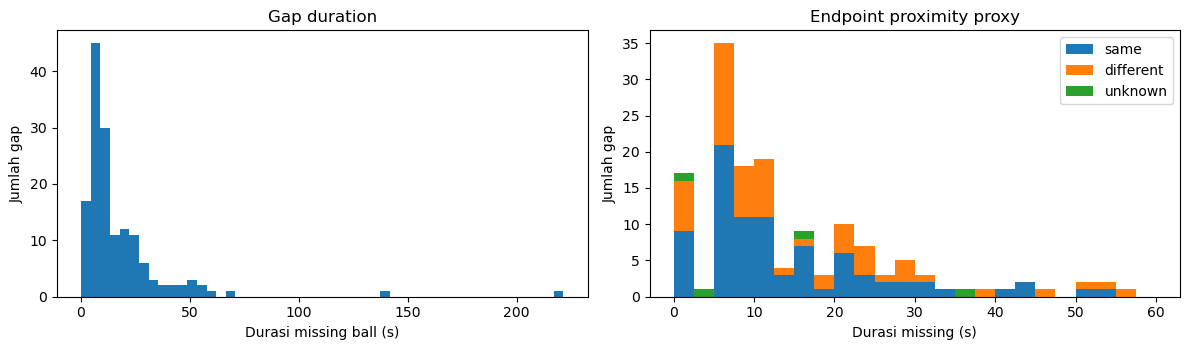

In [4]:
def true_runs(mask, offset=0):
    z=np.asarray(mask,dtype=bool)
    diff=np.diff(np.r_[False,z,False].astype(np.int8))
    starts=np.flatnonzero(diff==1)
    ends=np.flatnonzero(diff==-1)-1
    return pd.DataFrame({"start":starts+offset,"end":ends+offset,"nframes":ends-starts+1})

gaps=[]
for h,lo,hi in HALVES:
    local=true_runs(~ball_ok[lo:hi+1],lo)
    local["half"]=h
    gaps.append(local)
gaps=pd.concat(gaps,ignore_index=True)
gaps["seconds"]=gaps.nframes/FPS

def boundary_proxy(f,side):
    if f<0 or f>=N or half[f]!=side or not ball_ok[f]: return "?"
    return nearest_team[f]
gaps["proxy_before"]=[boundary_proxy(int(r.start)-1,int(r.half)) for r in gaps.itertuples()]
gaps["proxy_after"]=[boundary_proxy(int(r.end)+1,int(r.half)) for r in gaps.itertuples()]
gaps["boundary_relation"]=np.select([
    (gaps.proxy_before==gaps.proxy_after)&gaps.proxy_before.isin(["H","A"]),
    (gaps.proxy_before!=gaps.proxy_after)&gaps.proxy_before.isin(["H","A"])&gaps.proxy_after.isin(["H","A"])
],["same_proxy","different_proxy"],default="not_observable")
print("Missing gap count:",len(gaps))
display(gaps.seconds.describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_frame("seconds"))
display(gaps.boundary_relation.value_counts().to_frame("gaps"))
display(gaps.groupby("boundary_relation").seconds.agg(["count","median","mean","max"]))
fig,axs=plt.subplots(1,2,figsize=(12,3.6))
axs[0].hist(gaps.seconds,bins=50)
axs[0].set(xlabel="Durasi missing ball (s)",ylabel="Jumlah gap",title="Gap duration")
axs[1].hist([gaps.loc[gaps.boundary_relation==v,"seconds"] for v in ["same_proxy","different_proxy","not_observable"]],bins=np.linspace(0,min(60,max(5,gaps.seconds.max())),25),label=["same","different","unknown"],stacked=True)
axs[1].set(xlabel="Durasi missing (s)",ylabel="Jumlah gap",title="Endpoint proximity proxy")
axs[1].legend()
plt.tight_layout();plt.show()

## 4. Smart Tagging: normalisasi interval dan feature per frame

Kode tag diubah ke upper-case untuk analisis, `Team` diidentifikasi eksplisit, dan interval ditafsirkan sementara sebagai `[start_frame, end_frame)`. **Ini bukan batas restart/dead ball ground truth**. Fitur hitung jumlah event overlap, jumlah tag per tim, dan flag SET PIECES tanpa memaksakan satu tag dominan.

In [5]:
events=sportscode.load(str(PATHS["smart_tagging"])).to_df().copy()
assert {"timestamp","end_timestamp","code"}.issubset(events.columns)

def to_seconds(s):
    if pd.api.types.is_timedelta64_dtype(s): return s.dt.total_seconds()
    if pd.api.types.is_numeric_dtype(s): return pd.to_numeric(s,errors="coerce").astype(float)
    return pd.to_timedelta(s,errors="coerce").dt.total_seconds()

events["start_s"]=to_seconds(events.timestamp)
events["end_s"]=to_seconds(events.end_timestamp)
events["start_frame"]=np.rint(events.start_s*FPS).astype("Int64")
events["end_frame"]=np.rint(events.end_s*FPS).astype("Int64")
events["code_clean"]=events.code.astype(str).str.strip().str.upper()
if "Team" in events:
    names=events.Team.fillna("").astype(str).str.lower()
    events["side"] = np.select([names.str.contains("barcelona"),names.str.contains("athletic|atletic")],["H","A"],default="?")
else:
    events["side"]="?"

valid_events=events.dropna(subset=["start_frame","end_frame"]).copy()
valid_events=valid_events.loc[valid_events.end_frame>valid_events.start_frame]
print("Tag events:",len(events),"| valid intervals:",len(valid_events))
print("Codes:")
display(events.code_clean.value_counts().to_frame("instances"))
print("Team tags:")
display(events.side.value_counts().to_frame("instances"))

def interval_counts(subset):
    diff=np.zeros(N+1,dtype=np.int32)
    for s,e in subset[["start_frame","end_frame"]].itertuples(index=False,name=None):
        lo=max(0,min(N,int(s)));hi=max(0,min(N,int(e)))
        if lo<hi:
            diff[lo]+=1;diff[hi]-=1
    return np.cumsum(diff[:-1])

tag_count=interval_counts(valid_events)
tag_h=interval_counts(valid_events.loc[valid_events.side=="H"])
tag_a=interval_counts(valid_events.loc[valid_events.side=="A"])
setpiece_mask=interval_counts(valid_events.loc[valid_events.code_clean=="SET PIECES"])>0
for name,val in [("active_tag_count",tag_count),("active_h_tags",tag_h),("active_a_tags",tag_a),("set_piece_tag",setpiece_mask)]:
    features[name]=val
print("Tag coverage on graded frames:",round(100*(tag_count[grading]>0).mean(),2),"%")
print("H/A concurrent tagging frames:",int((grading&(tag_h>0)&(tag_a>0)).sum()))
print("Set-piece tagged frames:",int((grading&setpiece_mask).sum()))

Tag events: 638 | valid intervals: 638
Codes:


,instances
code_clean,
PLAYERS IN THE BOX,97
BALL IN FINAL THIRD,93
BALL IN THE BOX,72
PROGRESSION,66
DEFENDING IN MIDDLE THIRD,66
SET PIECES,59
CREATING CHANCES,30
DEFENDING IN DEFENSIVE THIRD,30
LONG BALL,29


Team tags:


,instances
side,
H,314
A,288
?,36


Tag coverage on graded frames: 82.27 %
H/A concurrent tagging frames: 66993
Set-piece tagged frames: 43899


## 5. Apakah missing ball berasosiasi dengan jenis tag?

Laporan ini **deskriptif**: proporsi ball observed di dalam interval tag, jumlah frame, dan perbandingan terhadap cakupan umum. Interval tag overlap; kategori **tidak saling eksklusif**. Analisis ini tidak memberikan label dead-ball.

,tag,instances,graded_frames_covered,ball_observed_%,missing_ball_%,mean_players
11,PLAYERS IN THE BOX,97,72639,57.55,42.45,20.96
1,BALL IN FINAL THIRD,93,58690,68.00,32.00,21.13
13,SET PIECES,59,43899,68.07,31.93,21.09
7,DEFENDING IN MIDDLE THIRD,66,31118,92.80,7.20,21.64
12,PROGRESSION,66,31118,92.80,7.20,21.64
2,BALL IN THE BOX,72,28965,70.00,30.00,20.95
4,CREATING CHANCES,30,22384,57.26,42.74,21.02
6,DEFENDING IN DEFENSIVE THIRD,30,22384,57.26,42.74,21.02
9,GOALS,4,16503,11.66,88.34,16.21
3,BUILD UP,22,11011,92.73,7.27,21.59


Overall graded missing ball %: 40.69


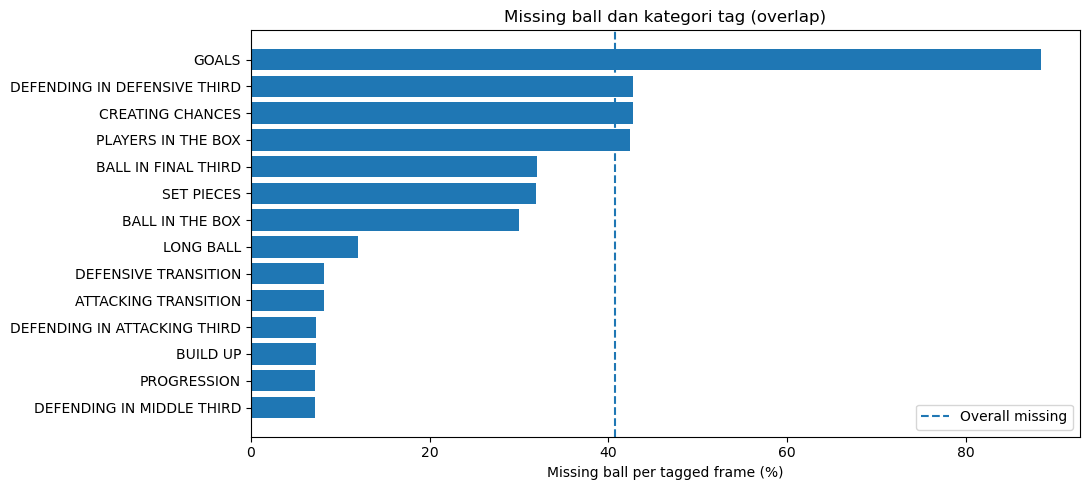

In [6]:
summary=[]
for code_name,grp in valid_events.groupby("code_clean"):
    is_active=interval_counts(grp)>0
    mask=grading&is_active
    if not mask.any():continue
    summary.append({
        "tag":code_name,"instances":len(grp),"graded_frames_covered":int(mask.sum()),
        "ball_observed_%":round(100*ball_ok[mask].mean(),2),
        "missing_ball_%":round(100*(~ball_ok[mask]).mean(),2),
        "mean_players":round(float((count_h[mask]+count_a[mask]).mean()),2)
    })
coverage_by_tag=pd.DataFrame(summary).sort_values("graded_frames_covered",ascending=False)
display(coverage_by_tag)
print("Overall graded missing ball %:",round(100*(~ball_ok[grading]).mean(),2))
fig,ax=plt.subplots(figsize=(11,5))
sub=coverage_by_tag.sort_values("missing_ball_%",ascending=True)
ax.barh(sub.tag,sub["missing_ball_%"])
ax.axvline(100*(~ball_ok[grading]).mean(),ls="--",label="Overall missing")
ax.set(xlabel="Missing ball per tagged frame (%)",title="Missing ball dan kategori tag (overlap)")
ax.legend();plt.tight_layout();plt.show()

## 6. Konteks missing gap: tag yang aktif di sekitar gap

Hitung fraksi frame dalam gap yang memiliki tag dan set-piece tag. Ini membantu memprioritaskan jenis gap untuk analisis video, tetapi tidak mengidentifikasi event yang sebenarnya.

Missing gaps overlapping at least 1 SET PIECES tag: 71 of 150


gaps  median_gap_s  median_tag_coverage  \
boundary_relation has_setpiece_tag                                            
different_proxy   False               25          9.36                 1.00   
                  True                35         12.44                 1.00   
not_observable    False                3         17.20                 0.00   
                  True                 1          0.08                 1.00   
same_proxy        False               51          9.16                 0.68   
                  True                35         12.04                 1.00   

                                    mean_player_count  
boundary_relation has_setpiece_tag                     
different_proxy   False                         20.84  
                  True                          20.79  
not_observable    False                          8.11  
                  True                          20.00  
same_proxy        False                         21.21  
                  True                          20.72

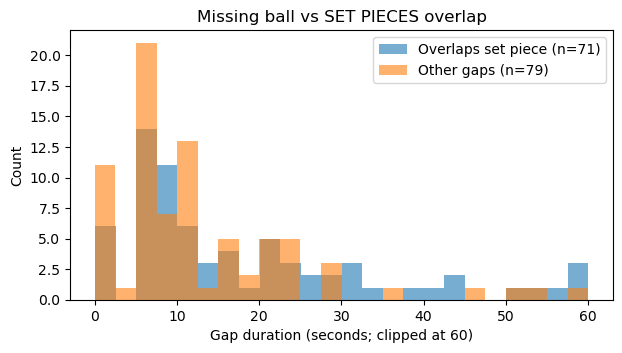

In [7]:
def fraction_over_interval(values,start,end):
    z=np.asarray(values)
    return float(z[int(start):int(end)+1].mean()) if end>=start else np.nan

gaps["tag_coverage_fraction"]=[fraction_over_interval(tag_count>0,r.start,r.end) for r in gaps.itertuples()]
gaps["setpiece_fraction"]=[fraction_over_interval(setpiece_mask,r.start,r.end) for r in gaps.itertuples()]
gaps["mean_tracked_players"]=[fraction_over_interval(count_h+count_a,r.start,r.end) for r in gaps.itertuples()]
gaps["has_setpiece_tag"]=gaps.setpiece_fraction>0
print("Missing gaps overlapping at least 1 SET PIECES tag:",int(gaps.has_setpiece_tag.sum()),"of",len(gaps))
display(gaps.groupby(["boundary_relation","has_setpiece_tag"]).agg(
    gaps=("seconds","size"),median_gap_s=("seconds","median"),median_tag_coverage=("tag_coverage_fraction","median"),
    mean_player_count=("mean_tracked_players","mean")
).round(2))
fig,ax=plt.subplots(figsize=(7,3.5))
for v,label in [(True,"Overlaps set piece"),(False,"Other gaps")]:
    s=gaps.loc[gaps.has_setpiece_tag==v,"seconds"]
    if len(s): ax.hist(s.clip(upper=60),bins=24,alpha=.6,label=f"{label} (n={len(s)})")
ax.set(xlabel="Gap duration (seconds; clipped at 60)",ylabel="Count",title="Missing ball vs SET PIECES overlap")
ax.legend();plt.show()

## 7. Proximity: apakah kandidat tim terdekat cepat berubah?

Perubahan H/A di sini adalah **proxy nearest-team**, bukan pergantian possession yang benar. Isolasi run hanya pada frame dengan bola dan kedua tim terlacak; gap `?` memutus run. Lihat berapa banyak run sangat pendek untuk memahami noise geometris.

Nearest-team proxy segments: 1948


,seconds
count,1948.000000
mean,1.930801
std,2.684022
min,0.040000
10%,0.200000
25%,0.440000
50%,0.920000
75%,2.400000
90%,4.840000
95%,6.720000


,window_frames,segments_shorter,share_%
0,3,65,3.3
1,5,154,7.9
2,10,416,21.4
3,25,1009,51.8
4,50,1351,69.4


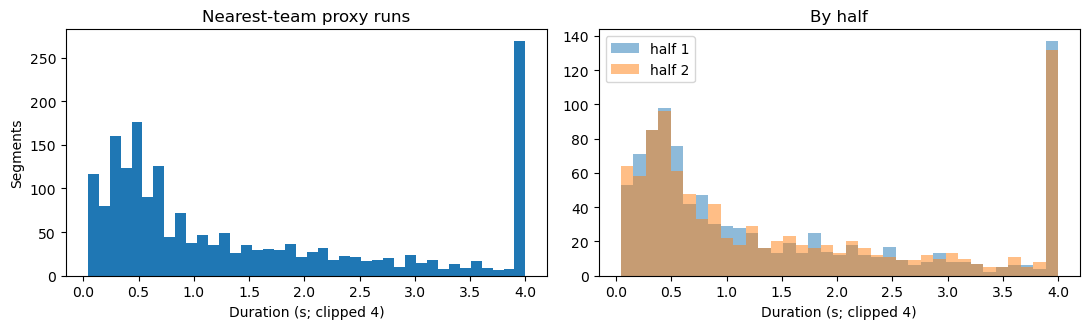

In [8]:
proxy_runs=[]
for h,lo,hi in HALVES:
    vals=nearest_team[lo:hi+1]
    # continuous runs of H or A, including '?' as separator
    boundaries=np.r_[0,np.flatnonzero(vals[1:]!=vals[:-1])+1,len(vals)]
    for b0,b1 in zip(boundaries[:-1],boundaries[1:]):
        side=vals[b0]
        if side in ("H","A"):
            proxy_runs.append({"half":h,"side":side,"start":lo+b0,"end":lo+b1-1,"frames":b1-b0,"seconds":(b1-b0)/FPS})
proxy_runs=pd.DataFrame(proxy_runs)
print("Nearest-team proxy segments:",len(proxy_runs))
display(proxy_runs.seconds.describe(percentiles=[.1,.25,.5,.75,.9,.95]).to_frame("seconds"))
display(pd.DataFrame([{"window_frames":n,"segments_shorter":int((proxy_runs.frames<n).sum()),"share_%":round(100*(proxy_runs.frames<n).mean(),1)} for n in (3,5,10,25,50)]))
fig,axs=plt.subplots(1,2,figsize=(11,3.4))
axs[0].hist(proxy_runs.seconds.clip(upper=4),bins=40)
axs[0].set(xlabel="Duration (s; clipped 4)",ylabel="Segments",title="Nearest-team proxy runs")
for h in (1,2):
    s=proxy_runs.loc[proxy_runs.half==h,"seconds"]
    axs[1].hist(s.clip(upper=4),bins=35,alpha=.5,label=f"half {h}")
axs[1].set(xlabel="Duration (s; clipped 4)",title="By half")
axs[1].legend();plt.tight_layout();plt.show()

## 8. Geometric ambiguity: margin kedua tim dan kualitas observasi

Bandingkan besarnya margin jarak antartim pada frame yang valid, dengan distribusi kecepatan bola dan jumlah pemain. Jangan memutuskan threshold berdasarkan skor GT publik. Band yang ditampilkan di sini berbasis **kuantil observasi**, hanya untuk diagnosis.

Absolute margin quantiles (m):


,abs_margin_m
0.10,0.579014
0.25,1.481007
0.50,3.529415
0.75,7.273543
0.90,11.720135


,frames,median_abs_margin_m,median_ball_speed2d_mps,mean_tracked_home,mean_tracked_away
margin_quartile,,,,,
Q1 ambiguous-ish,23508,0.72,6.64,10.75,10.79
Q2,23507,2.40,6.13,10.72,10.73
Q3,23507,5.12,4.94,10.75,10.73
Q4 separated,23508,10.60,3.29,10.72,10.54


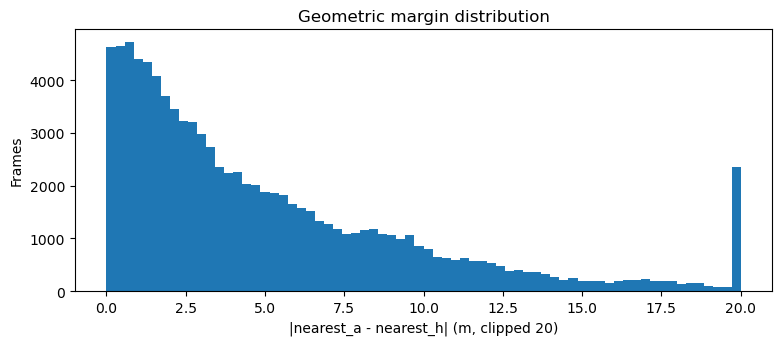

In [9]:
geom=features.loc[grading&both,["nearest_h_m","nearest_a_m","distance_margin_a_minus_h_m","ball_speed2d_mps","home_count","away_count"]].copy()
geom["abs_margin_m"]=geom.distance_margin_a_minus_h_m.abs()
q=geom.abs_margin_m.quantile([.1,.25,.5,.75,.9]).to_frame("abs_margin_m")
print("Absolute margin quantiles (m):")
display(q)
# Quartile bands are descriptive only, not production thresholds.
geom["margin_quartile"]=pd.qcut(geom.abs_margin_m,4,labels=["Q1 ambiguous-ish","Q2","Q3","Q4 separated"],duplicates="drop")
display(geom.groupby("margin_quartile",observed=True).agg(
    frames=("abs_margin_m","size"),median_abs_margin_m=("abs_margin_m","median"),
    median_ball_speed2d_mps=("ball_speed2d_mps","median"),mean_tracked_home=("home_count","mean"),
    mean_tracked_away=("away_count","mean")
).round(2))
fig,ax=plt.subplots(figsize=(9,3.4))
ax.hist(geom.abs_margin_m.clip(upper=20),bins=70)
ax.set(xlabel="|nearest_a - nearest_h| (m, clipped 20)",ylabel="Frames",title="Geometric margin distribution")
plt.show()

## 9. Pemain tetap berguna saat bola hilang?

Analisis jumlah pemain dan gerak kolektif tim ketika bola ada/tidak ada. Pergerakan centroid tim di sini **bukan indikator possession langsung** dan dapat dipengaruhi identitas track yang berubah. Kita hanya menilai ketersediaan fitur untuk model tanpa bola.

In [10]:
def team_centroid(side):
    mask=(side_arr==side)
    x=np.where(valid_players[:,mask],px[:,mask],np.nan)
    y=np.where(valid_players[:,mask],py[:,mask],np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore",RuntimeWarning)
        cx=np.nanmean(x,axis=1)
        cy=np.nanmean(y,axis=1)
    return cx,cy

centroids={}
centroid_motion={}
for side in ("H","A"):
    cx,cy=team_centroid(side)
    centroids[side]=(cx,cy)
    s=np.full(N,np.nan)
    ok=np.isfinite(cx[1:])&np.isfinite(cx[:-1])&np.isfinite(cy[1:])&np.isfinite(cy[:-1])
    ok &= (half[1:]==half[:-1])&(half[1:]!=0)
    ds=np.hypot(np.diff(cx)*PITCH_L,np.diff(cy)*PITCH_W)
    s[1:][ok]=ds[ok]*FPS
    centroid_motion[side]=s
    features[f"centroid_speed_{side}_mps"]=s

rows=[]
for label,mask in [("ball_present",grading&ball_ok),("ball_missing",grading&~ball_ok)]:
    rows.append({"condition":label,"frames":int(mask.sum()),
        "mean_players_H":round(float(count_h[mask].mean()),2),
        "mean_players_A":round(float(count_a[mask].mean()),2),
        "median_centroid_speed_H_mps":round(float(np.nanmedian(centroid_motion["H"][mask])),2),
        "median_centroid_speed_A_mps":round(float(np.nanmedian(centroid_motion["A"][mask])),2),
        "both_teams_>=8_players_%":round(100*np.mean((count_h[mask]>=8)&(count_a[mask]>=8)),2)})
display(pd.DataFrame(rows))
for side in ("H","A"):
    print(f"Centroid motion {side} availability on missing ball:",round(100*np.isfinite(centroid_motion[side][grading&~ball_ok]).mean(),2),"%")

,condition,frames,mean_players_H,mean_players_A,median_centroid_speed_H_mps,median_centroid_speed_A_mps,both_teams_>=8_players_%
0,ball_present,94214,10.71,10.68,1.42,1.49,97.51
1,ball_missing,64643,9.45,9.71,0.59,0.57,81.57


Centroid motion H availability on missing ball: 99.13 %
Centroid motion A availability on missing ball: 100.0 %


## 10. SET PIECES: fitur di sekitar START dan END interval

Bandingkan peristiwa dengan agregat temporal di sekitar awal/akhir tag; **start/end tag belum tentu waktu live/dead yang benar**. Plot dibatasi dalam babak yang sama; titik di luar range tidak dicampur. Metrik: ball presence, count pemain, kecepatan bola observasi, proximity, dan tag aktif.

SET PIECES records: 59


,instances
Type,
Throw-in,26
Corner Kick,12
Goal Kick,10
Free Kick,5
Kick Off (After Goal),4
Kick Off (Start),2


start_frame: usable anchors in graded halves: 58


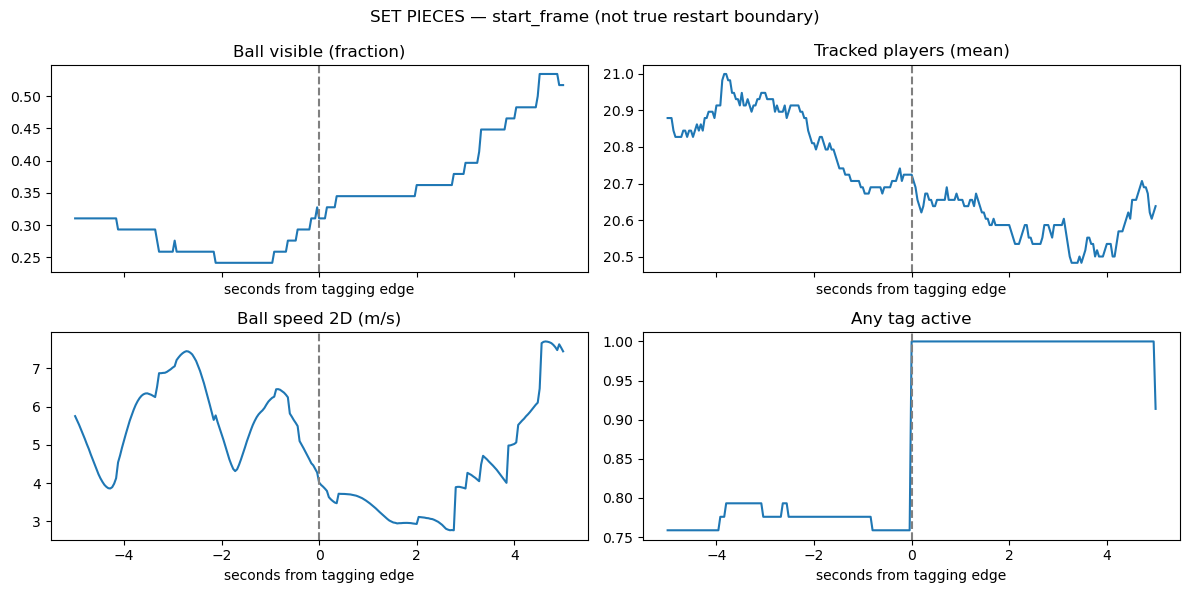

end_frame: usable anchors in graded halves: 59


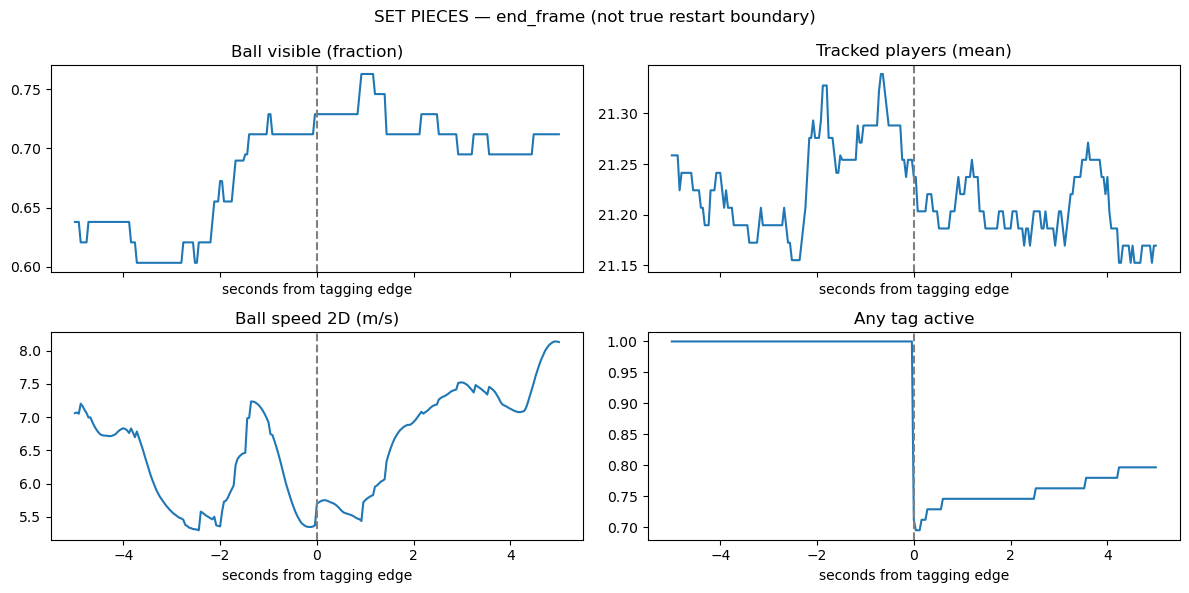

In [11]:
setpieces=valid_events.loc[valid_events.code_clean=="SET PIECES"].copy()
print("SET PIECES records:",len(setpieces))
if "Type" in setpieces:
    display(setpieces["Type"].fillna("N/A").astype(str).value_counts().to_frame("instances"))

rel=np.arange(-5*FPS,5*FPS+1)
def time_curve(metric,anchors,halves_for_anchors):
    arr=np.asarray(metric,dtype=float)
    mat=np.full((len(anchors),len(rel)),np.nan)
    for k,(a,h) in enumerate(zip(anchors,halves_for_anchors)):
        indices=a+rel
        ok=(indices>=0)&(indices<N)
        idx=indices[ok]
        pos=np.flatnonzero(ok)
        same=half[idx]==h
        mat[k,pos[same]]=arr[idx[same]]
    ct=np.isfinite(mat).sum(axis=0)
    return np.divide(np.nansum(mat,axis=0),ct,out=np.full(len(rel),np.nan),where=ct>0), ct

metrics={"Ball visible (fraction)":ball_ok.astype(float),
         "Tracked players (mean)":(count_h+count_a).astype(float),
         "Ball speed 2D (m/s)":ball_speed2d,
         "Any tag active":(tag_count>0).astype(float)}
for edge in ("start_frame","end_frame"):
    anchor_all=setpieces[edge].dropna().astype(int).to_numpy()
    keep=(anchor_all>=0)&(anchor_all<N)
    anchors=anchor_all[keep]
    anchor_half=half[anchors]
    choose=anchor_half>0
    anchors=anchors[choose];anchor_half=anchor_half[choose]
    print(f"{edge}: usable anchors in graded halves:",len(anchors))
    if not len(anchors):continue
    fig,axs=plt.subplots(2,2,figsize=(12,6),sharex=True)
    for ax,(label,v) in zip(axs.flat,metrics.items()):
        mean,ct=time_curve(v,anchors,anchor_half)
        ax.plot(rel/FPS,mean)
        ax.axvline(0,ls="--",color="gray")
        ax.set(title=label,xlabel="seconds from tagging edge")
    fig.suptitle("SET PIECES — "+edge+" (not true restart boundary)")
    plt.tight_layout();plt.show()

## 11. Kandidat anomali tracking bola dan reliability

P99 dan maksimum dari kecepatan 2D hanya indikator diagnostik, bukan batas fisik untuk menolak data. Gerak bola melayang serta error tracking perlu dibedakan. Periksa juga ketersediaan seluruh optional ATD fields (tanpa menggunakannya sebagai GT).

In [12]:
speed_gr=ball_speed2d[grading & np.isfinite(ball_speed2d)]
quantiles=np.quantile(speed_gr,[.5,.9,.95,.99,.999]) if len(speed_gr) else np.full(5,np.nan)
display(pd.DataFrame({"quantile":["p50","p90","p95","p99","p99.9"],"speed2d_mps":quantiles}))
print("Max speed 2D proxy:",np.nanmax(speed_gr) if len(speed_gr) else None)
# Distribution of high-movement events based on quantiles for QA only, not filtering.
if len(speed_gr):
    high=grading & (ball_speed2d>np.quantile(speed_gr,.99))
    print("Top 1% speed proxy frames:",int(high.sum()),"| with SET PIECES active:",int((high&setpiece_mask).sum()))
    print("Player count in high-speed frames (median):",float(np.median((count_h+count_a)[high])))

optional=[]
for col in ["ball_state","ball_owning_team_id","ball_z","ball_speed"]:
    if col in atd.columns:
        s=atd[col]
        nonnull=s.notna().sum()
        optional.append({"column":col,"dtype":str(s.dtype),"non_null":int(nonnull),"non_null_%":round(100*nonnull/N,2),
                        "example_values":str(s.dropna().astype(str).unique()[:5].tolist())[:180]})
    else:
        optional.append({"column":col,"dtype":"ABSENT","non_null":0,"non_null_%":0,"example_values":""})
display(pd.DataFrame(optional))
print("Catatan: optional fields dapat berasal dari pipeline otomatis; jika non-null, verifikasi semantik dan provenance sebelum digunakan.")

,quantile,speed2d_mps
0,p50,5.081759
1,p90,14.309995
2,p95,17.351455
3,p99,24.603603
4,p99.9,54.609895


Max speed 2D proxy: 109.59787966968157
Top 1% speed proxy frames: 941 | with SET PIECES active: 273
Player count in high-speed frames (median): 21.0


,column,dtype,non_null,non_null_%,example_values
0,ball_state,object,0,0.0,[]
1,ball_owning_team_id,object,0,0.0,[]
2,ball_z,object,0,0.0,[]
3,ball_speed,object,0,0.0,[]


Catatan: optional fields dapat berasal dari pipeline otomatis; jika non-null, verifikasi semantik dan provenance sebelum digunakan.


## 12. Homography quality & pemilihan interval pemeriksaan video

Cek kualitas homography di graded halves dan pada gap yang kandidat proksimitasnya berubah. Trigger video di sini adalah **hipotesis kebutuhan** (missing gap dengan endpoint proxy berbeda / overlap set piece), bukan ground truth atau parameter final. `reprojection_error` tidak otomatis berunit pixel.

In [13]:
hom=pd.read_csv(PATHS["homography"])
H_COLS=[f"h{i}{j}" for i in range(3) for j in range(3)]
assert len(hom)==N and np.array_equal(pd.to_numeric(hom.frame,errors="coerce").to_numpy(),frame)
assert set(H_COLS+["valid","reprojection_error"]).issubset(hom.columns)
hom_valid=pd.to_numeric(hom.valid,errors="coerce").fillna(0).to_numpy()==1
h_error=pd.to_numeric(hom.reprojection_error,errors="coerce").to_numpy(float)
print("Valid homographies:",int(hom_valid.sum()),"/",N)
display(pd.Series(h_error[grading]).describe(percentiles=[.5,.9,.95,.99]).to_frame("reprojection_error"))

# Video diagnostic intervals: only endpoints+setpiece evidence; no manually curated timeline.
gaps["suggest_video_check"]=(gaps.boundary_relation=="different_proxy") | (gaps.has_setpiece_tag)
print("Suggested video-check gaps:",int(gaps.suggest_video_check.sum()),"/",len(gaps))
print("Total candidate video-check seconds (may overlap; no actual video decoded):",round(float(gaps.loc[gaps.suggest_video_check,"seconds"].sum()),1))
display(gaps.groupby("suggest_video_check").agg(
    gaps=("seconds","size"),median_length_s=("seconds","median"),total_duration_s=("seconds","sum"),
    median_setpiece_fraction=("setpiece_fraction","median")).round(2))

# Inspect homography error in candidate intervals, without exporting frame data.
err_per_gap=[]
for r in gaps.itertuples():
    e=h_error[int(r.start):int(r.end)+1]
    err_per_gap.append(float(np.nanmedian(e)) if np.isfinite(e).any() else np.nan)
gaps["median_reprojection_error"]=err_per_gap
display(gaps.groupby("suggest_video_check").median_reprojection_error.describe().round(3))

Valid homographies: 199319 / 199319


,reprojection_error
count,158857.000000
mean,0.296384
std,0.511894
min,0.062284
50%,0.230840
90%,0.307819
95%,0.356650
99%,4.295122
max,5.453117


Suggested video-check gaps: 96 / 150
Total candidate video-check seconds (may overlap; no actual video decoded): 1853.3


,gaps,median_length_s,total_duration_s,median_setpiece_fraction
suggest_video_check,,,,
False,54,9.88,732.40,0.00
True,96,10.96,1853.32,0.32


,count,mean,std,min,25%,50%,75%,max
suggest_video_check,,,,,,,,
False,54.0,0.396,0.823,0.158,0.207,0.234,0.251,4.782
True,96.0,0.283,0.482,0.168,0.210,0.232,0.257,4.946


## 13. Visual QA opsional (tanpa menyimpan cuplikan)

Tampilkan frame dengan overlay tracking untuk memeriksa integritas geometri, **bukan** melakukan koreksi manual label atau membuat frame-specific rules. Sampling hanya dari anchor `games.py` atau sampel terpilih otomatis dari statistik data. Tidak pernah mengekspor video, frame, atau koordinat. Jika `cv2` belum tersedia, sel ini melewati visualisasi tanpa menghentikan eksplorasi.

In [17]:
%pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Showing deterministic kickoff anchor: 11186


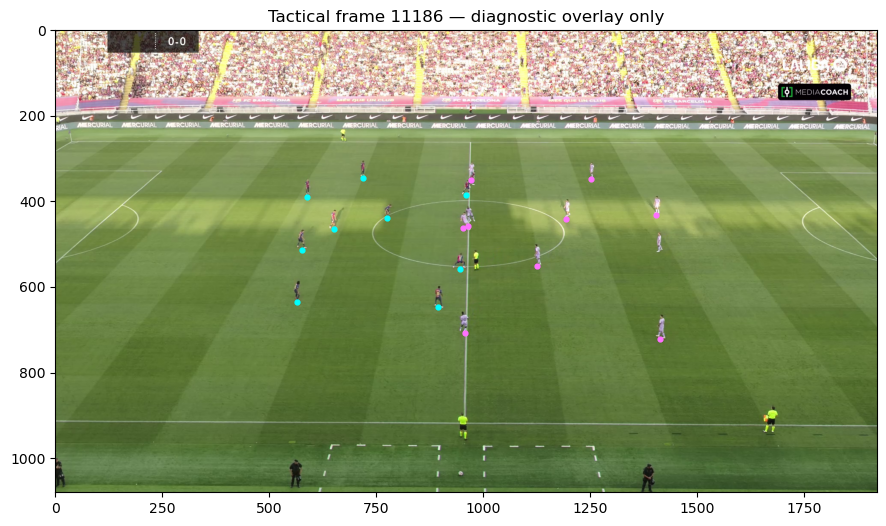

In [18]:
def project(H,x,y):
    uvw=H@np.array([x,y,1.0],dtype=float)
    if not np.isfinite(uvw).all() or abs(uvw[2])<1e-10:return (np.nan,np.nan)
    return (uvw[0]/uvw[2],uvw[1]/uvw[2])

def show_overlay(f):
    try:
        import cv2
    except ImportError:
        print("Skip video QA: instal opencv-python terlebih dulu jika perlu")
        return
    if not PATHS["video"].is_file():
        print("Skip video QA: video tidak ditemukan:",PATHS["video"])
        return
    if not (0<=f<N):return
    cap=cv2.VideoCapture(str(PATHS["video"]))
    try:
        cap.set(cv2.CAP_PROP_POS_FRAMES,int(f))
        ok,bgr=cap.read()
    finally:
        cap.release()
    if not ok:
        print("Video decode failed at frame",f);return
    rgb=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB)
    fig,ax=plt.subplots(figsize=(11,6))
    ax.imshow(rgb)
    if hom_valid[f] and np.isfinite(h_error[f]):
        H=hom.iloc[f][H_COLS].to_numpy(dtype=float).reshape(3,3)
        for j in range(len(slots)):
            if valid_players[f,j]:
                u,v=project(H,px[f,j],py[f,j])
                if np.isfinite([u,v]).all():ax.scatter([u],[v],s=12,c="#00FFFF" if side_arr[j]=="H" else "#FF70FF")
        if ball_ok[f]:
            u,v=project(H,bx[f],by[f])
            if np.isfinite([u,v]).all():ax.scatter([u],[v],s=115,facecolors="none",edgecolors="yellow",linewidths=2)
    ax.set(xlim=(0,rgb.shape[1]),ylim=(rgb.shape[0],0),title=f"Tactical frame {f} — diagnostic overlay only")
    plt.show()

# Deterministic, supplied anchor; do not hand-pick mispredicted frames.
SHOW_OPTIONAL_VIDEO_QA = True
if SHOW_OPTIONAL_VIDEO_QA:
    anchor=games.anchor_video_frame(games.GAMES[GAME]["kickoff"])
    print("Showing deterministic kickoff anchor:",anchor)
    show_overlay(anchor)
else:
    print("Video QA disabled. Set SHOW_OPTIONAL_VIDEO_QA=True to view one deterministic frame locally.")

## 14. Feature-contract preview, conclusions, and next actions

**Jangan salah baca hasil:**
- `nearest_team_proxy` = tim dengan pemain terdekat saat bola terdeteksi, **bukan** truth possession.
- `SET PIECES` dan tag fase bukan interval dead-ball yang tepat.
- Gap panjang bukan bukti dead-ball.
- Perbedaan distribusi tidak membuktikan fitur bisa memprediksi label tanpa pengujian yang sah.

**Keputusan setelah notebook:**
1. Konfirmasi apakah optional ball fields memang berisi data; jika berisi, audit provenance/semantiknya.
2. Tentukan input feature contract (kolom, satuan, aturan NaN, alignment, metadata tim) dari hasil audit.
3. Buat *dead/live evidence* dan *H/A control evidence* terpisah, lalu temporal decoder sederhana.
4. Uji logika di kasus sintetis dan/atau pertandingan lain yang legal; lima menit GT publik hanya untuk sanity-check pipeline, bukan tuning.
5. Tambahkan video sebagai pemeriksaan otomatis selektif setelah dapat mengukur apakah data tracking+tagging cukup.

Tidak ada penyimpanan derived tracking atau visual ke repository / file publik.

In [19]:
feature_contract = pd.DataFrame([
    ("frame","int","video frame 0-based; 0..N-1"),
    ("half","int","0 non-graded, 1/2 evaluated halves"),
    ("ball_ok","bool","observed ball x/y both finite"),
    ("home_count / away_count","int","count of valid team track slots"),
    ("nearest_h_m / nearest_a_m","float/NaN","minimum 2D ball-to-player distance, metres"),
    ("distance_margin_a_minus_h_m","float/NaN","positive means H closer; NOT H ownership"),
    ("nearest_team_proxy","str","H/A/? from geometry; never a possession label"),
    ("ball_speed2d_mps","float/NaN","consecutive observed ball displacement only"),
    ("active_tag_count","int","number of overlapping Smart Tagging intervals"),
    ("active_h_tags / active_a_tags","int","number of team-associated overlapping tags"),
    ("set_piece_tag","bool","automatically tagged set-piece interval (not exact dead ball)"),
    ("centroid_speed_H_mps / centroid_speed_A_mps","float/NaN","team-centroid displacement proxy"),
],columns=["feature","dtype","meaning / caveat"])
display(feature_contract)
print("Prepared in-memory feature table:",features.shape,"| no files written")
print("Remaining open questions: calibration without match GT; dead/live boundaries; temporal control proof; effective video triggers")

,feature,dtype,meaning / caveat
0,frame,int,video frame 0-based; 0..N-1
1,half,int,"0 non-graded, 1/2 evaluated halves"
2,ball_ok,bool,observed ball x/y both finite
3,home_count / away_count,int,count of valid team track slots
4,nearest_h_m / nearest_a_m,float/NaN,"minimum 2D ball-to-player distance, metres"
5,distance_margin_a_minus_h_m,float/NaN,positive means H closer; NOT H ownership
6,nearest_team_proxy,str,H/A/? from geometry; never a possession label
7,ball_speed2d_mps,float/NaN,consecutive observed ball displacement only
8,active_tag_count,int,number of overlapping Smart Tagging intervals
9,active_h_tags / active_a_tags,int,number of team-associated overlapping tags


Prepared in-memory feature table: (199319, 17) | no files written
Remaining open questions: calibration without match GT; dead/live boundaries; temporal control proof; effective video triggers
